# Tutorial 7: Noise statistics of FDMT and DDMT

Does FDMT leave white noise white? With `use_box_smearing=False` it does: once
its history is complete, its output has the same distribution as direct
dedispersion (DDMT). This notebook checks that, together with the
fractional-delay engines FDMT-FFT and DDMT-FFT. Box-smeared FDMT is kept as a
control that should *not* be white.

Three things can make FDMT output of Gaussian noise look non-white, and this
notebook looks at each:

1. **Box smearing** averages each channel over its smearing window, so noise
   power falls toward high Fourier frequencies, more so at high DM;
2. with the same filter, powers near Nyquist no longer follow the
   chi-square law a white spectrum would give;
3. a **cold start** on data with a nonzero mean adds a low-frequency excess
   even without box smearing.

The first two are why `use_box_smearing` is an option; section 1 explains the
filter. The third is shown in section 4: it goes away once the startup samples
are dropped. This notebook covers noise only; for signal recovery see the
{doc}`periodicity guide <../pipeline_guide/periodicity>`.

## 1. Why the output should be white

Without box smearing, each output sample of a DM trial is the sum of one
sample per channel, the sample at that channel's upper-edge arrival time. For
independent unit-variance channels the sum has variance `nchans`. Two
different output times use different samples of every channel, so they are
uncorrelated. Rounding delays to whole samples changes how well a *signal*
lines up, but it cannot correlate the noise. A fractional delay, as in
FDMT-FFT or DDMT-FFT, is a pure phase ramp and does not correlate it either.

Box smearing (the default) instead averages each channel over a window of
$L_c$ samples with weight $w_c \approx 1/L_c$. Neighbouring outputs share
samples, and the output covariance is

$$R_y[\ell] = \sum_c w_c^2\max(L_c-|\ell|,0).$$

That is a low-pass filter on the noise, and no single scale factor undoes it.
In `dmt` the window has $L = |dt|+1$ taps and ends at the current sample.

For white output, each Fourier power divided by its known expectation follows
an exponential distribution (chi-square with two degrees of freedom, halved).
DC and the Nyquist bin have only one degree of freedom, so they are left out
of that test.

In [1]:
from pathlib import Path
import importlib.util
import numpy as np
import matplotlib.pyplot as plt

# Run from a repository checkout with dmtlib, NumPy and matplotlib installed.
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "bench/scripts/fdmt_noise.py").is_file())
spec = importlib.util.spec_from_file_location(
    "fdmt_noise", repo / "bench/scripts/fdmt_noise.py")
noise = importlib.util.module_from_spec(spec)
spec.loader.exec_module(noise)

## 2. Setting up the experiment

Each beam is one independent realisation of the same Gaussian input, and every
engine gets the same blocks. DDMT and DDMT-FFT run at FDMT's effective DMs, so
the grids match. A warmup block longer than every engine's `startup_samples`
comes first, then two blocks are measured.

The engines put time zero at different frequencies (FDMT at `f_min`, DDMT at
the centre of the top channel), so we compare distributions, not individual
samples.

In [2]:
streams, plan, configuration = noise.collect_noise(
    nchans=32, nsamps=1024, realizations=256,
    dt_grid=[0, 128, 512], blocks=2, seed=20261103,
)
{k: configuration[k] for k in ("dt_grid", "dm_grid", "warmup_blocks", "startup_samples")}

{'dt_grid': [0, 128, 512],
 'dm_grid': [0.0, 6.580907344818115, 26.32362937927246],
 'warmup_blocks': 1,
 'startup_samples': {'fdmt': 512, 'fdmt_fft': 641}}

## 3. The checks

For each engine and DM trial we test:

- **the mean and variance**, against the known values;
- **the autocovariance** at a few nonzero lags;
- **the mean power** in every Fourier bin;
- **the distribution of power** in a few fixed bins against the exponential
  law. Bins 1, 2 and 4 cover the low-frequency question, and the bins just
  below Nyquist cover the high-frequency one.

The distribution test uses the independent beams at one fixed bin. It never
pools neighbouring bins or DM trials, which are correlated. No noise scale is
fitted. The bounds are conservative (Gaussian and chi-square tail bounds, and
the Dvoretzky–Kiefer–Wolfowitz bound) with a total false-alarm budget of
$10^{-6}$ across all checks, so a pass is meaningful. It is still evidence for
these configurations, not a proof about every tail. Box-smeared FDMT should
fail at nonzero DM: the filter is doing its job.

In [3]:
report = noise.analyze(streams, plan, alpha=1e-6)
for name, rows in report.items():
    print(name)
    for delay, dm, row in zip(plan.dt_grid_final, plan.dm_grid_final, rows):
        print(f"  delay={delay:4d}, DM={dm:7.3f}: white={row['passed']!s:5}, "
              f"variance/nchans={row['energy']:.4f}, "
              f"max fixed-bin CDF distance={max(row['cdf_distance'].values()):.3f} "
              f"(bound {row['cdf_bound']:.3f})")
assert all(r["passed"] for name in noise.WHITE_ENGINES for r in report[name])
assert not report["fdmt_box"][-1]["passed"]

fdmt_raw
  delay=   0, DM=  0.000: white=True , variance/nchans=1.0046, max fixed-bin CDF distance=0.072 (bound 0.216)
  delay= 128, DM=  6.581: white=True , variance/nchans=1.0020, max fixed-bin CDF distance=0.076 (bound 0.216)
  delay= 512, DM= 26.324: white=True , variance/nchans=0.9976, max fixed-bin CDF distance=0.062 (bound 0.216)
fdmt_box
  delay=   0, DM=  0.000: white=True , variance/nchans=1.0046, max fixed-bin CDF distance=0.072 (bound 0.216)
  delay= 128, DM=  6.581: white=False, variance/nchans=0.2380, max fixed-bin CDF distance=0.893 (bound 0.216)
  delay= 512, DM= 26.324: white=False, variance/nchans=0.0798, max fixed-bin CDF distance=0.979 (bound 0.216)
fdmt_fft_raw
  delay=   0, DM=  0.000: white=True , variance/nchans=1.0046, max fixed-bin CDF distance=0.074 (bound 0.216)
  delay= 128, DM=  6.581: white=True , variance/nchans=1.0020, max fixed-bin CDF distance=0.078 (bound 0.216)
  delay= 512, DM= 26.324: white=True , variance/nchans=0.9976, max fixed-bin CDF distance

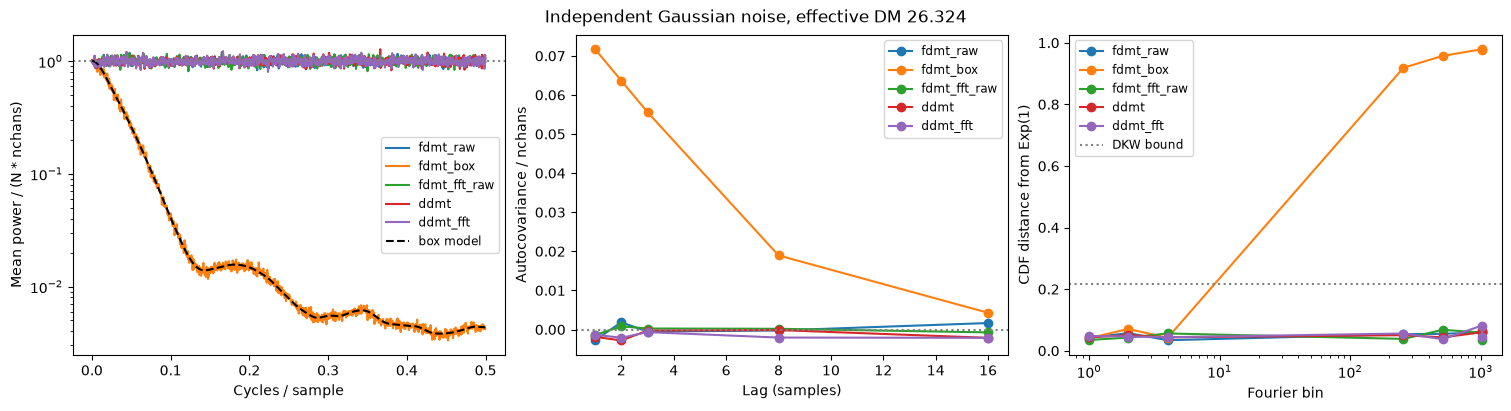

In [4]:
fig = noise.plot_analysis(report, plan)
plt.show()

The plot shows the highest DM. The unfiltered engines sit on a flat line at
one, with no correlation at nonzero lags and small distribution distances.
Box-smeared FDMT follows the predicted spectrum (dashed). Its distribution
distance is measured against the *white* expectation, so it mostly shows the
change of scale.

## 4. The cold start

FDMT in `mode="valid"` returns `nsamps` outputs per call, so blocks join
exactly. Output sample `t` needs input back to `t - startup_samples`. Right
after construction or `reset_history()` that past does not exist: it is
zero-filled. This is the **cold start**. The first `startup_samples` outputs
are then sums over only some of the channels, and they are written like any
other sample. DDMT instead withholds samples it cannot compute yet.

With zero-mean input this only lowers the variance at the start. Real
filterbank data have a nonzero mean, and then those partial sums form a ramp.
The ramp lengthens with DM and puts a lot of power into the lowest Fourier
bins. Here we add 1 to every input sample and remove each series' mean, as a
power-spectrum pipeline would:

In [5]:
cold = noise.cold_start_noise(mean=1.0, nchans=32, nsamps=8192,
                              realizations=128, delay=2048)
print("startup_samples:", cold["startup_samples"])
for name in ("fdmt_cold", "fdmt_trimmed", "ddmt"):
    row = cold[name]
    print(f"{name:13s} white={row['passed']!s:5}  mean power, bins 1-4: "
          f"{np.round(row['spectral_mean'][1:5], 2)}")
assert not cold["fdmt_cold"]["passed"]
assert cold["fdmt_trimmed"]["passed"] and cold["ddmt"]["passed"]

startup_samples: 2048
fdmt_cold     white=False  mean power, bins 1-4: [6502.61 3891.58 1514.49  322.6 ]
fdmt_trimmed  white=True   mean power, bins 1-4: [1.18 0.94 1.12 1.07]
ddmt          white=True   mean power, bins 1-4: [1.21 0.96 1.11 1.08]


Dropping the first `startup_samples` outputs (`fdmt_trimmed`) makes the
output white again, just like DDMT.

```{warning}
In a streaming search this happens once per observation: mask candidates in
that stretch, or fill the history with real data first. Don't call
`reset_history()` between consecutive blocks.
```

The same thing with constant input:

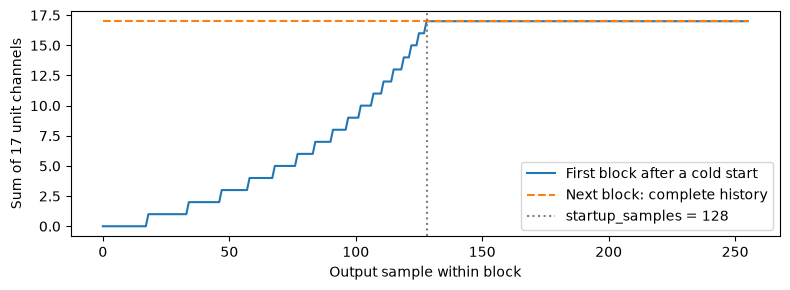

In [6]:
f = noise.FDMT(400., 800., 17, 256, .001,
               dt_grid=np.array([128], dtype=np.int64),
               use_box_smearing=False, mode="valid")
ones = np.ones((17, 256), dtype=np.float32)
cold_block, warm_block = f.execute(ones), f.execute(ones)
s = f.startup_samples
plt.figure(figsize=(8, 3))
plt.plot(cold_block[0], label="First block after a cold start")
plt.plot(warm_block[0], "--", label="Next block: complete history")
plt.axvline(s, color="grey", linestyle=":", label=f"startup_samples = {s}")
plt.xlabel("Output sample within block")
plt.ylabel("Sum of 17 unit channels")
plt.legend()
plt.tight_layout()
plt.show()

## 5. A time series in one call

For offline work, `dmtlib.dedisperse` runs one waterfall through an engine,
drops the startup samples, and returns the effective DMs and the time
reference. `arrival_times()` converts each engine's convention to a common
one, by default infinite frequency.

In [7]:
from dmtlib import dedisperse

rng = np.random.default_rng(1)
wf = rng.standard_normal((64, 16384), dtype=np.float32) + 10.0
for engine in ("fdmt", "fdmt_fft", "ddmt"):
    r = dedisperse(wf, 400.0, 800.0, 0.001, [0.0, 100.0], engine=engine)
    print(f"{engine:8s} dms={np.round(r.dms, 3)}  f_ref={r.f_ref:.3f} MHz  "
          f"start={r.start}  nout={r.data.shape[1]}  "
          f"std/sqrt(nchans)={np.round(r.data.std(axis=1) / 8, 3)}")

fdmt     dms=[ 0.    99.999]  f_ref=400.000 MHz  start=1945  nout=14439  std/sqrt(nchans)=[1.007 1.   ]
fdmt_fft dms=[ 0.    99.999]  f_ref=400.000 MHz  start=2010  nout=14310  std/sqrt(nchans)=[1.007 0.991]
ddmt     dms=[  0. 100.]  f_ref=796.875 MHz  start=0  nout=14484  std/sqrt(nchans)=[1.005 1.001]


## What to use

:::{admonition} Takeaways
:class: dmt-summary

For a periodicity search, or any analysis of the power spectrum:

- set **`use_box_smearing=False`**. It is already the default in `dedisperse`,
  but not in the engine classes;
- pass the band edges as `f_min` and `f_max`;
- keep the history across blocks, and drop `startup_samples` once per
  observation;
- if signal near Nyquist matters, use FDMT-FFT or DDMT-FFT. Integer FDMT keeps
  the noise white but loses signal at the highest Fourier frequencies at
  high DM.
:::

```{note}
These results assume independent channels with equal variance and no missing
samples. Correlated channels, changing masks, quantisation, RFI and estimated
spectral normalisation all need their own checks.
```

:::{dropdown} Running the same analysis from the command line
:icon: terminal

```sh
python bench/scripts/fdmt_noise.py --cold-start-mean 1.0 --output /tmp/fdmt-noise --plot
python bench/scripts/fdmt_noise.py --backend cuda --output /tmp/fdmt-noise-cuda --plot
python bench/scripts/tone_recovery.py --dm 200
python -m pytest tests/python/test_fdmt_noise.py tests/python/test_dedisperse.py
```

`fdmt_noise.py` writes a JSON file with the configuration, seed, extension
path and every diagnostic. It exits with an error if an engine that should be
white fails, or if the trimmed FDMT or DDMT fail the cold-start check.
:::